T12-T13 : résultats finaux, tests et conclusions

Ce notebook rassemble les prévisions de tous les modèles (HAR, HAR-X, log-HAR, log-HAR-X, LightGBM avec et sans VIX, GARCH, GJR, EGARCH) à h = 1, 5 et 22 jours sur le S&P 500 et le TSX, pour la période de test 2015-01-02 → 2026-09-10 (2026-09-09 pour le TSX). Les comparaisons utilisent la QLIKE et le MSE, et le test de Diebold-Mariano contre le HAR (erreur HAC). Le test de Mincer-Zarnowitz vérifie si les prévisions sont calibrées (a = 0, b = 1). Le HAR-X est un HAR en niveaux auquel on ajoute le VIX, estimé ici avec des coefficients contraints positifs (constante comprise). Le log-HAR et le log-HAR-X (notebook `04b_log_har`) sont les mêmes régressions estimées sur les logarithmes : ils doivent être exécutés avant ce notebook.

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p/"data"/"features_spx.csv").exists())
sys.path.append(str(root))

from src.utils import (TEST_START, save_forecasts, load_all_forecasts,
                       evaluate, dm_test, qlike, mse)

FEAT = {k: pd.read_csv(root/"data"/f"features_{k}.csv", index_col=0, parse_dates=True)
        for k in ("spx", "tsx")}

for ix in ("spx", "tsx"):
    fc = load_all_forecasts(ix)
    print(ix.upper(), "| modèles :", sorted(fc["model"].unique()))
    print("   lignes par modèle :", fc.groupby("model").size().to_dict())

SPX | modèles : ['EGARCH', 'GARCH', 'GJR', 'HAR', 'HARX', 'LGBM', 'LGBM_noVIX', 'LOGHAR', 'LOGHARX']
   lignes par modèle : {'EGARCH': 8817, 'GARCH': 8817, 'GJR': 8817, 'HAR': 8817, 'HARX': 8817, 'LGBM': 8817, 'LGBM_noVIX': 8817, 'LOGHAR': 8817, 'LOGHARX': 8817}
TSX | modèles : ['EGARCH', 'GARCH', 'GJR', 'HAR', 'HARX', 'LGBM', 'LGBM_noVIX', 'LOGHAR', 'LOGHARX']
   lignes par modèle : {'EGARCH': 8799, 'GARCH': 8799, 'GJR': 8799, 'HAR': 8799, 'HARX': 8799, 'LGBM': 8799, 'LGBM_noVIX': 8799, 'LOGHAR': 8799, 'LOGHARX': 8799}


In [2]:
from sklearn.linear_model import LinearRegression

HORIZONS = [1, 5, 22]

def harx_walk_forward(index, refit=22):
    feat = FEAT[index]
    cols = ["rv_d", "rv_w", "rv_m", "vix"]
    # mêmes dates de test que les autres modèles
    dates = feat.index[(feat.index >= TEST_START) & feat["y_h22"].notna()]
    out = []
    for h in HORIZONS:
        for k, d in enumerate(dates):
            if k % refit == 0:                          # ré-estimation tous les 22 jours
                train = feat.loc[:d].iloc[:-h]          # seulement des cibles déjà connues
                model = LinearRegression(positive=True, fit_intercept=False).fit(
                    train[cols].assign(const=1.0), train[f"y_h{h}"])
            f = float(model.predict(feat.loc[[d], cols].assign(const=1.0))[0])
            out.append({"date": d, "model": "HARX", "horizon": h,
                        "forecast": max(f, 1e-4),
                        "actual": feat.loc[d, f"y_h{h}"]})
    return pd.DataFrame(out)

for ix in ("spx", "tsx"):
    df = harx_walk_forward(ix)
    save_forecasts(df, "HARX", ix)            # results/forecasts_<ix>_HARX.csv
    print(ix.upper(), len(df), "lignes | forecast min :", round(df["forecast"].min(), 4))

SPX 8817 lignes | forecast min : 0.1533


TSX 8799 lignes | forecast min : 0.137


In [3]:
for ix in ("spx", "tsx"):
    t = evaluate(ix)
    print("=====", ix.upper())
    display(t[t["model"].isin(["HAR", "HARX", "LGBM"])])

===== SPX


,horizon,model,QLIKE,MSE,DM vs HAR,p-value
3,1,HAR,0.3960,1.3104,NaN,NaN
4,1,HARX,0.4143,1.2769,4.1104,0.0000
5,1,LGBM,0.3421,1.1248,-6.4970,0.0000
12,5,HAR,0.2754,0.9952,NaN,NaN
13,5,HARX,0.2737,0.9570,-0.3228,0.7468
14,5,LGBM,0.2320,0.7283,-5.2434,0.0000
21,22,HAR,0.3127,0.8817,NaN,NaN
22,22,HARX,0.2987,0.8468,-1.8811,0.0600
23,22,LGBM,0.3164,0.7673,0.1220,0.9029


===== TSX


,horizon,model,QLIKE,MSE,DM vs HAR,p-value
3,1,HAR,0.3416,1.1488,NaN,NaN
4,1,HARX,0.3757,1.1326,8.2125,0.0000
5,1,LGBM,0.2968,0.9444,-8.0151,0.0000
12,5,HAR,0.2384,0.9970,NaN,NaN
13,5,HARX,0.2523,0.9762,2.7464,0.0060
14,5,LGBM,0.1959,0.9404,-5.2266,0.0000
21,22,HAR,0.3418,0.9754,NaN,NaN
22,22,HARX,0.3212,0.9561,-1.4000,0.1615
23,22,LGBM,0.3646,0.9390,0.2748,0.7835


In [4]:
# 1) Tables de résultats : tous les modèles, vs HAR
for ix in ("spx", "tsx"):
    t = evaluate(ix)
    t.to_csv(root/"results"/f"table4_resultats_{ix}.csv", index=False)
    print("=====", ix.upper())
    display(t)

# 2) Test direct : LightGBM avec VIX contre sans VIX
lignes = []
for ix in ("spx", "tsx"):
    fc = load_all_forecasts(ix)
    for h in HORIZONS:
        g = fc[(fc["horizon"] == h) & fc["model"].isin(["LGBM", "LGBM_noVIX"])]
        w = g.pivot(index="date", columns="model", values="forecast").dropna()
        y = g.drop_duplicates("date").set_index("date").loc[w.index, "actual"]
        t_dm, p = dm_test(y, w["LGBM"], w["LGBM_noVIX"], h)
        lignes.append({"indice": ix, "horizon": h, "DM": round(t_dm, 3), "p-value": round(p, 4)})

table_vix = pd.DataFrame(lignes)
table_vix.to_csv(root/"results"/"table_vix_dm.csv", index=False)
print("===== Test direct : LGBM (avec VIX) contre LGBM_noVIX (DM négatif = meilleur avec le VIX)")
display(table_vix)

===== SPX


,horizon,model,QLIKE,MSE,DM vs HAR,p-value
0,1,EGARCH,0.4060,1.1546,0.5520,0.5810
1,1,GARCH,0.4210,1.8802,2.7611,0.0058
2,1,GJR,0.3939,1.8964,-0.1583,0.8742
3,1,HAR,0.3960,1.3104,NaN,NaN
4,1,HARX,0.4143,1.2769,4.1104,0.0000
5,1,LGBM,0.3421,1.1248,-6.4970,0.0000
6,1,LGBM_noVIX,0.3671,1.2863,-4.0766,0.0000
7,1,LOGHAR,0.3839,1.3690,-2.5614,0.0104
8,1,LOGHARX,0.3394,1.0424,-8.6971,0.0000
9,5,EGARCH,0.3135,0.8471,1.3965,0.1626


===== TSX


,horizon,model,QLIKE,MSE,DM vs HAR,p-value
0,1,EGARCH,0.3336,1.0661,-0.8049,0.4209
1,1,GARCH,0.3529,1.7221,1.2136,0.2249
2,1,GJR,0.3377,1.7421,-0.4054,0.6852
3,1,HAR,0.3416,1.1488,NaN,NaN
4,1,HARX,0.3757,1.1326,8.2125,0.0000
5,1,LGBM,0.2968,0.9444,-8.0151,0.0000
6,1,LGBM_noVIX,0.3020,1.1134,-6.9295,0.0000
7,1,LOGHAR,0.3146,1.3482,-6.7418,0.0000
8,1,LOGHARX,0.3024,1.2147,-11.1086,0.0000
9,5,EGARCH,0.2145,0.8761,-1.8708,0.0614


===== Test direct : LGBM (avec VIX) contre LGBM_noVIX (DM négatif = meilleur avec le VIX)


,indice,horizon,DM,p-value
0,spx,1,-4.335,0.0000
1,spx,5,-2.890,0.0039
2,spx,22,-0.695,0.4873
3,tsx,1,-2.771,0.0056
4,tsx,5,-0.818,0.4133
5,tsx,22,1.155,0.2479


Test direct : LightGBM contre les benchmarks en log (T13)

Le HAR en niveaux minimise le MSE, alors que LightGBM (objectif gamma) minimise une perte équivalente à la QLIKE. On compare donc LightGBM aux benchmarks linéaires en log, à ensemble d'information comparable : LightGBM (avec VIX) contre log-HAR-X, et LightGBM sans VIX contre log-HAR. LightGBM utilise en plus `ret` et `ret_neg`. Statistique DM négative : LightGBM est meilleur.

In [5]:
lignes = []
for ix in ("spx", "tsx"):
    fc = load_all_forecasts(ix)
    for h in HORIZONS:
        g = fc[fc["horizon"] == h]
        w = g.pivot(index="date", columns="model", values="forecast").dropna()
        y = g.drop_duplicates("date").set_index("date").loc[w.index, "actual"]
        for m1, m2 in [("LGBM", "LOGHARX"), ("LGBM_noVIX", "LOGHAR")]:
            t_dm, p = dm_test(y, w[m1], w[m2], h)
            lignes.append({"indice": ix, "horizon": h, "comparaison": f"{m1} vs {m2}",
                           "QLIKE_1": round(qlike(y, w[m1]), 4), "QLIKE_2": round(qlike(y, w[m2]), 4),
                           "écart_%": round(100 * (qlike(y, w[m1]) / qlike(y, w[m2]) - 1), 1),
                           "DM": round(t_dm, 3), "p-value": round(p, 4)})

table_log = pd.DataFrame(lignes)
table_log.to_csv(root/"results"/"table_dm_lgbm_loghar.csv", index=False)
display(table_log)

,indice,horizon,comparaison,QLIKE_1,QLIKE_2,écart_%,DM,p-value
0,spx,1,LGBM vs LOGHARX,0.3421,0.3394,0.8,0.725,0.4682
1,spx,1,LGBM_noVIX vs LOGHAR,0.3671,0.3839,-4.4,-2.576,0.0100
2,spx,5,LGBM vs LOGHARX,0.2320,0.2286,1.5,1.119,0.2629
3,spx,5,LGBM_noVIX vs LOGHAR,0.2569,0.2684,-4.3,-1.736,0.0825
4,spx,22,LGBM vs LOGHARX,0.3164,0.2923,8.2,2.204,0.0276
5,spx,22,LGBM_noVIX vs LOGHAR,0.3258,0.3189,2.2,0.917,0.3591
6,tsx,1,LGBM vs LOGHARX,0.2968,0.3024,-1.8,-1.427,0.1536
7,tsx,1,LGBM_noVIX vs LOGHAR,0.3020,0.3146,-4.0,-2.329,0.0198
8,tsx,5,LGBM vs LOGHARX,0.1959,0.1952,0.4,0.123,0.9021
9,tsx,5,LGBM_noVIX vs LOGHAR,0.1985,0.2068,-4.0,-1.214,0.2247


In [6]:
import statsmodels.api as sm

def mz(y, f, h):
    X = sm.add_constant(pd.Series(np.asarray(f), name="forecast"))
    r = sm.OLS(np.asarray(y), X).fit(cov_type="HAC", cov_kwds={"maxlags": h})
    ft = r.f_test("const = 0, forecast = 1")
    return {"a": r.params["const"], "b": r.params["forecast"],
            "se_a": r.bse["const"], "se_b": r.bse["forecast"],
            "R2": r.rsquared,
            "F": float(np.squeeze(ft.fvalue)), "p_F(a=0,b=1)": float(ft.pvalue)}

lignes = []
for ix in ("spx", "tsx"):
    fc = load_all_forecasts(ix)
    for (m, h), g in fc.groupby(["model", "horizon"]):
        lignes.append({"indice": ix, "modèle": m, "horizon": h,
                       **mz(g["actual"], g["forecast"], h)})

table6 = pd.DataFrame(lignes).round(4)
table6.to_csv(root/"results"/"table6_mz.csv", index=False)
display(table6)

,indice,modèle,horizon,a,b,se_a,se_b,R2,F,"p_F(a=0,b=1)"
0,spx,EGARCH,1,0.0659,0.8280,0.0525,0.0930,0.5403,2.9578,0.0521
1,spx,EGARCH,5,0.1186,0.7597,0.0711,0.1301,0.5394,1.7270,0.1780
2,spx,EGARCH,22,0.2538,0.5776,0.0620,0.1115,0.2668,9.4831,0.0001
3,spx,GARCH,1,0.1959,0.5870,0.0496,0.0819,0.4306,14.1509,0.0000
4,spx,GARCH,5,0.2775,0.4735,0.0632,0.1073,0.4041,12.0311,0.0000
5,spx,GARCH,22,0.4486,0.2375,0.0593,0.0624,0.1703,82.2299,0.0000
6,spx,GJR,1,0.2058,0.5651,0.0392,0.0656,0.5200,23.2420,0.0000
7,spx,GJR,5,0.2803,0.4705,0.0516,0.0883,0.4952,18.1063,0.0000
8,spx,GJR,22,0.4448,0.2595,0.0591,0.0595,0.2065,84.7651,0.0000
9,spx,HAR,1,-0.0301,1.0013,0.0791,0.1400,0.4507,1.5497,0.2125


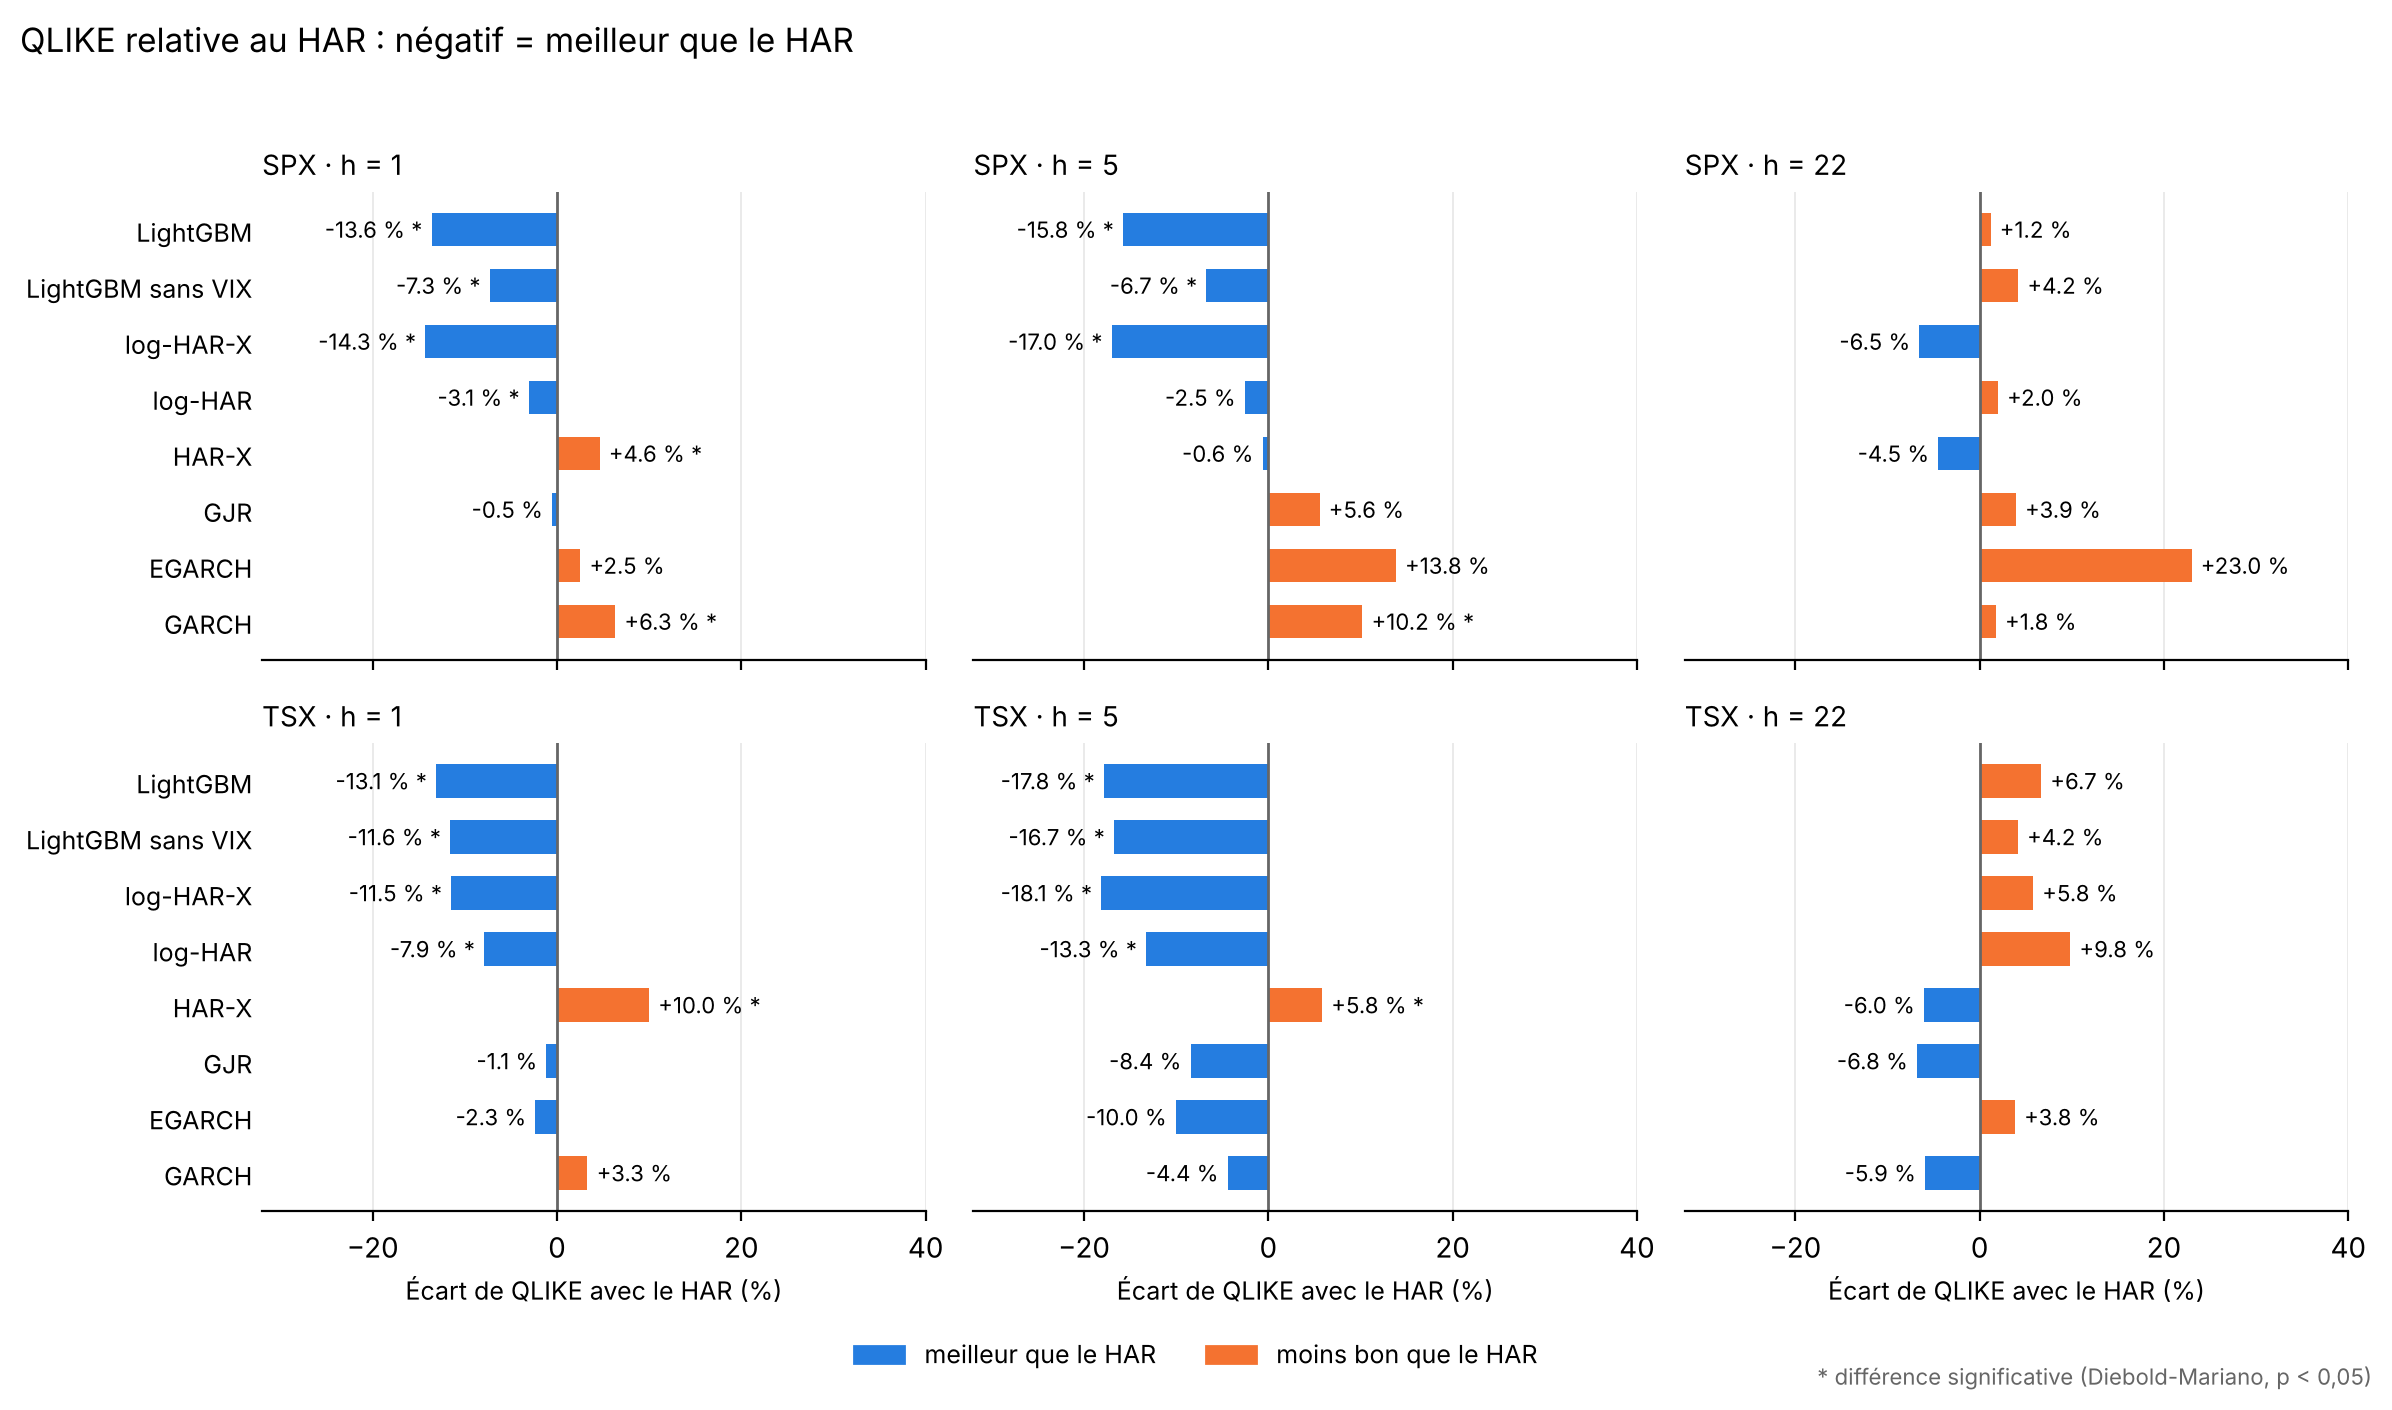

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

BLEU, ORANGE = "#257de0", "#f47230"     # mieux que le HAR / moins bon que le HAR
ORDRE = ["LGBM", "LGBM_noVIX", "LOGHARX", "LOGHAR", "HARX", "GJR", "EGARCH", "GARCH"]
NOMS  = {"LGBM": "LightGBM", "LGBM_noVIX": "LightGBM sans VIX", "HARX": "HAR-X",
         "LOGHAR": "log-HAR", "LOGHARX": "log-HAR-X",
         "GJR": "GJR", "EGARCH": "EGARCH", "GARCH": "GARCH"}

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
for i, ix in enumerate(("spx", "tsx")):
    t = evaluate(ix)
    for j, h in enumerate(HORIZONS):
        ax = axes[i, j]
        g = t[t["horizon"] == h].set_index("model")
        har = g.loc["HAR", "QLIKE"]
        rel = ((g["QLIKE"] / har - 1) * 100).reindex(ORDRE)      # écart en % avec le HAR
        sig = (g["p-value"] < 0.05).reindex(ORDRE)               # significatif (DM vs HAR)
        y = range(len(ORDRE))
        ax.barh(y, rel.values, height=0.6,
                color=[BLEU if v < 0 else ORANGE for v in rel.values])
        ax.axvline(0, color="#666666", lw=1)
        for yy, v, s in zip(y, rel.values, sig.values):
            ax.text(v + (1 if v >= 0 else -1), yy, f"{v:+.1f} %" + (" *" if s else ""),
                    va="center", ha="left" if v >= 0 else "right", fontsize=8)
        ax.set_yticks(list(y)); ax.set_yticklabels([NOMS[m] for m in ORDRE], fontsize=9)
        ax.set_title(f"{ix.upper()} · h = {h}", fontsize=10, loc="left")
        ax.grid(axis="x", color="#e6e6e6", lw=0.6); ax.set_axisbelow(True)
        for s_ in ("top", "right", "left"): ax.spines[s_].set_visible(False)
        ax.tick_params(axis="y", length=0)

axes[0, 0].set_xlim(-32, 40)
axes[0, 0].invert_yaxis()               # LightGBM en haut (axe partagé : une seule fois)
for ax in axes[1]: ax.set_xlabel("Écart de QLIKE avec le HAR (%)", fontsize=9)
fig.suptitle("QLIKE relative au HAR : négatif = meilleur que le HAR", fontsize=12, x=0.01, ha="left")
fig.legend(handles=[Patch(color=BLEU, label="meilleur que le HAR"),
                    Patch(color=ORANGE, label="moins bon que le HAR")],
           loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0.0))
fig.text(0.99, 0.005, "* différence significative (Diebold-Mariano, p < 0,05)",
         ha="right", fontsize=8, color="#666666")
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
(root/"figures").mkdir(exist_ok=True)
fig.savefig(root/"figures"/"fig5_qlike_relative.png", dpi=150)
plt.show()

Conclusions (provisoires, mises à jour avec T13)

**LightGBM contre le HAR en niveaux.** À h = 1 et 5, LightGBM a une QLIKE inférieure de 13 à 18 % à celle du HAR sur les deux indices (Diebold-Mariano, p < 0,001). À h = 22, aucun modèle n'est significativement meilleur que le HAR.

**Mais un benchmark linéaire en log fait aussi bien.** Le log-HAR-X bat lui aussi le HAR à h = 1 et 5 (−14,3 % et −17,0 % sur le S&P 500, −11,5 % et −18,1 % sur le TSX, p < 0,001). Dans le test direct, LightGBM et le log-HAR-X ne sont significativement différents à aucun horizon de 1 ou 5 jours (p entre 0,15 et 0,90). À h = 22 sur le S&P 500, le log-HAR-X est même meilleur que LightGBM (QLIKE 0,292 contre 0,316, p = 0,028). L'essentiel du gain de LightGBM sur le HAR vient donc de deux éléments qu'un modèle linéaire peut aussi exploiter : une estimation cohérente avec la QLIKE (log ou objectif gamma, au lieu des MCO en niveaux, qui minimisent le MSE) et le VIX.

**Ce que la non-linéarité ajoute.** Sans VIX, LightGBM bat le log-HAR à h = 1 (−4,4 % sur le S&P 500, p = 0,010 ; −4,0 % sur le TSX, p = 0,020), mais pas de façon significative à h = 5 et 22. Ce gain peut venir de la non-linéarité ou des variables `ret` et `ret_neg`, que le log-HAR n'a pas. Une fois le VIX ajouté, LightGBM n'apporte plus de gain détectable par rapport au log-HAR-X.

**Le VIX.** Il améliore LightGBM à h = 1 et 5 sur le S&P 500 et à h = 1 sur le TSX (test direct, p < 0,01). Ajouté en niveaux au HAR (HAR-X), il dégrade la QLIKE à h = 1 (+4,6 % et +10,0 %, p < 0,001) ; mais la contrainte de positivité force la constante à 0 et le VIX est une volatilité alors que la cible est une variance. En log, le même VIX améliore nettement le HAR : la dégradation du HAR-X vient de la spécification, pas d'une non-linéarité que seul le ML saurait capter. L'élasticité estimée sur 2000-2014 est d'environ 1,6 pour le S&P 500 et 0,4 pour le TSX à h = 1 : le VIX, indice américain, renseigne beaucoup moins sur le marché canadien.

**GARCH.** Les modèles de la famille GARCH ne battent jamais le HAR de façon significative, et le GARCH(1,1) est significativement moins bon sur le S&P 500 à h = 1 et 5. D'après Mincer-Zarnowitz, leurs prévisions sont trop dispersées (b ≈ 0,5 à 0,6 à h = 1), alors que celles du HAR, du log-HAR-X et de LightGBM sont proches de la calibration à h = 1 et 5 sur le S&P 500.

**Limites.** Le projet compte 84 tests de Diebold-Mariano : après la correction de Holm (`07_robustesse`, table 9), 24 rejets sur 37 survivent, dont tous les résultats principaux contre le HAR ; le p = 0,028 à h = 22 et plusieurs effets du VIX ne survivent pas. Les différences non significatives ne prouvent pas que deux modèles sont équivalents. La grille de réglage de LightGBM touche son bord (num_leaves = 7 dans 8 cas sur 12, min_child_samples = 50 dans 10 cas sur 12) ; une grille élargie ne change presque pas la QLIKE de test (`07_robustesse`, table 10). Le HAR en niveaux est sensible à la donnée douteuse du TSX du 2008-10-14, conservée dans les résultats (table 11) ; sans elle, LightGBM reste significativement meilleur que le HAR au TSX à h = 1 (−9,2 % au lieu de −13,1 %). L'avantage de LightGBM sur le log-HAR-X dépend du régime : meilleur en 2020, moins bon en 2015-2019 (table 8). LightGBM est ré-estimé tous les 66 jours contre 22 pour les modèles linéaires, ce qui le désavantage légèrement. À h = 22, toutes les prévisions sont trop dispersées (b < 1). Le retour aux niveaux du log-HAR suppose des résidus normaux en log (correction exp(σ²/2)) ; l'estimateur de Duan donne pratiquement la même QLIKE (voir `04b_log_har`). Nous n'avons pas testé d'autres estimateurs de variance (Parkinson, Rogers-Satchell) : la cible de Garman-Klass ne contient pas le saut de nuit, et le choix de l'estimateur pourrait modifier le classement des modèles.